DATA-VIZ HACK-A-BIT (2026–2027)

Course: 24ADI204 – Data Science and Visualization
Project: Flight Data 2024 Analysis
Team Number: 10

WEEK 1 – DATASET SELECTION AND SETUP

Objective:
To select a real-world dataset, download it using KaggleHub,
and understand the basic use of Pandas and NumPy for data analysis.




In [ ]:
!pip -q install kagglehub pandas numpy matplotlib seaborn

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
dataset_path = kagglehub.dataset_download(
    "hrishitpatil/flight-data-2024"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

100%|██████████| 270M/270M [00:12<00:00, 23.3MB/s]

Extracting files...


Dataset downloaded successfully!
Dataset location: /root/.cache/kagglehub/datasets/hrishitpatil/flight-data-2024/versions/2


In [ ]:
csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

if not csv_candidates:
    raise FileNotFoundError("Dataset CSV file not found.")

file_path = csv_candidates[0]

print("Dataset file:", file_path)
print("File size (GB):",
      round(os.path.getsize(file_path) / (1024**3), 2))

Dataset file: /kaggle/input/flight-data-2024/flight_data_2024.csv
File size (GB): 1.22


In [ ]:
sample_df = pd.read_csv(file_path, nrows=5)

print("First five rows of the dataset:")
display(sample_df)

First five rows of the dataset:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237.0,0,0,0,0,0


In [ ]:
print("Number of rows in sample:", sample_df.shape[0])
print("Number of columns:", sample_df.shape[1])

print("\nColumn names:")
print(sample_df.columns.tolist())

print("\nData types:")
print(sample_df.dtypes)

Number of rows in sample: 5
Number of columns: 35

Column names:
['year', 'month', 'day_of_month', 'day_of_week', 'fl_date', 'op_unique_carrier', 'op_carrier_fl_num', 'origin', 'origin_city_name', 'origin_state_nm', 'dest', 'dest_city_name', 'dest_state_nm', 'crs_dep_time', 'dep_time', 'dep_delay', 'taxi_out', 'wheels_off', 'wheels_on', 'taxi_in', 'crs_arr_time', 'arr_time', 'arr_delay', 'cancelled', 'cancellation_code', 'diverted', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']

Data types:
year                     int64
month                    int64
day_of_month             int64
day_of_week              int64
fl_date                 object
op_unique_carrier       object
op_carrier_fl_num      float64
origin                  object
origin_city_name        object
origin_state_nm         object
dest                    object
dest_city_name          object
dest_state_nm          

In [ ]:
numbers = np.array([10, 20, 30, 40, 50])

print("NumPy Array:", numbers)
print("Mean:", np.mean(numbers))
print("Maximum:", np.max(numbers))
print("Minimum:", np.min(numbers))
print("Standard Deviation:", np.std(numbers))

NumPy Array: [10 20 30 40 50]
Mean: 30.0
Maximum: 50
Minimum: 10
Standard Deviation: 14.142135623730951


In [ ]:
print("PROJECT DATASET DETAILS")
print("-----------------------")
print("Dataset Name: Flight Data 2024")
print("Source: Kaggle")
print("Dataset ID: hrishitpatil/flight-data-2024")
print("File Name: flight_data_2024.csv")
print("Project Team: Team 10")
print("Course: 24ADI204 – Data Science and Visualization")

PROJECT DATASET DETAILS
-----------------------
Dataset Name: Flight Data 2024
Source: Kaggle
Dataset ID: hrishitpatil/flight-data-2024
File Name: flight_data_2024.csv
Project Team: Team 10
Course: 24ADI204 – Data Science and Visualization


WEEK 1 – CONCLUSION

During this week, we selected the Flight Data 2024 dataset
from Kaggle. We downloaded the dataset using KaggleHub and
examined a small sample of the available records.

We also practised basic operations using Pandas and NumPy.
The dataset contains flight-related information that will
be used to study departure delays, arrival delays and other
flight-related patterns in the upcoming weeks.

# WEEK 2 – KNOW YOUR DATA

## Objective

To load the complete Flight Data 2024 dataset and understand its structure, size, column names, data types and initial data quality. A First Impression Report is generated to summarize the dataset.


### Introduction

In this week, we explore the complete Flight Data 2024 dataset to understand the information it contains. We inspect the number of records, columns, data types, missing values and duplicate records. This initial inspection helps us understand the dataset before performing data cleaning and analysis.


In [1]:
!pip -q install pandas numpy matplotlib seaborn kagglehub

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset_path = kagglehub.dataset_download("hrishitpatil/flight-data-2024")

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/flight-data-2024


In [3]:
csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

if not csv_candidates:
    raise FileNotFoundError("Dataset file not found!")

file_path = csv_candidates[0]

print("CSV File:", file_path)
print("File Size:", round(os.path.getsize(file_path)/(1024**3), 2), "GB")

CSV File: /kaggle/input/flight-data-2024/flight_data_2024.csv
File Size: 1.22 GB


In [4]:
df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (7079081, 35)


In [5]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Records:", len(df))

Total Rows: 7079081
Total Columns: 35
Total Records: 7079081


In [6]:
print("Columns in the Dataset:\n")

for column in df.columns:
    print(column)

Columns in the Dataset:

year
month
day_of_month
day_of_week
fl_date
op_unique_carrier
op_carrier_fl_num
origin
origin_city_name
origin_state_nm
dest
dest_city_name
dest_state_nm
crs_dep_time
dep_time
dep_delay
taxi_out
wheels_off
wheels_on
taxi_in
crs_arr_time
arr_time
arr_delay
cancelled
cancellation_code
diverted
crs_elapsed_time
actual_elapsed_time
air_time
distance
carrier_delay
weather_delay
nas_delay
security_delay
late_aircraft_delay


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7079081 entries, 0 to 7079080
Data columns (total 35 columns):
 #   Column               Dtype  
---  ------               -----  
 0   year                 int64  
 1   month                int64  
 2   day_of_month         int64  
 3   day_of_week          int64  
 4   fl_date              object 
 5   op_unique_carrier    object 
 6   op_carrier_fl_num    float64
 7   origin               object 
 8   origin_city_name     object 
 9   origin_state_nm      object 
 10  dest                 object 
 11  dest_city_name       object 
 12  dest_state_nm        object 
 13  crs_dep_time         int64  
 14  dep_time             float64
 15  dep_delay            float64
 16  taxi_out             float64
 17  wheels_off           float64
 18  wheels_on            float64
 19  taxi_in              float64
 20  crs_arr_time         int64  
 21  arr_time             float64
 22  arr_delay            float64
 23  cancelled            int64  
 24

In [8]:
print("First Five Records:")
display(df.head())

First Five Records:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024,1,1,1,2024-01-01,9E,4814.0,JFK,"New York, NY",New York,...,0,136.0,122.0,84.0,509.0,0,0,0,0,0
1,2024,1,1,1,2024-01-01,9E,4815.0,MSP,"Minneapolis, MN",Minnesota,...,0,130.0,114.0,88.0,622.0,0,0,0,0,0
2,2024,1,1,1,2024-01-01,9E,4817.0,JFK,"New York, NY",New York,...,0,106.0,90.0,61.0,288.0,0,0,0,0,0
3,2024,1,1,1,2024-01-01,9E,4817.0,RIC,"Richmond, VA",Virginia,...,0,111.0,76.0,51.0,288.0,0,0,0,0,0
4,2024,1,1,1,2024-01-01,9E,4818.0,DTW,"Detroit, MI",Michigan,...,0,79.0,70.0,45.0,237.0,0,0,0,0,0


In [9]:
print("Last Five Records:")
display(df.tail())

Last Five Records:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
7079076,2024,12,31,2,2024-12-31,YX,5857.0,MYR,"Myrtle Beach, SC",South Carolina,...,0,117.0,102.0,76.0,563.0,0,0,0,0,0
7079077,2024,12,31,2,2024-12-31,YX,5859.0,JFK,"New York, NY",New York,...,0,89.0,72.0,51.0,273.0,0,0,0,0,0
7079078,2024,12,31,2,2024-12-31,YX,5859.0,PWM,"Portland, ME",Maine,...,0,89.0,83.0,50.0,273.0,0,0,0,0,0
7079079,2024,12,31,2,2024-12-31,YX,5862.0,JFK,"New York, NY",New York,...,0,89.0,81.0,42.0,209.0,0,0,0,0,0
7079080,2024,12,31,2,2024-12-31,YX,5863.0,SYR,"Syracuse, NY",New York,...,0,83.0,72.0,47.0,209.0,0,0,0,0,0


In [10]:
print("Random Five Records:")
display(df.sample(5, random_state=42))

Random Five Records:


,year,month,day_of_month,day_of_week,fl_date,op_unique_carrier,op_carrier_fl_num,origin,origin_city_name,origin_state_nm,...,diverted,crs_elapsed_time,actual_elapsed_time,air_time,distance,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
1996999,2024,4,18,4,2024-04-18,MQ,3535.0,DFW,"Dallas/Fort Worth, TX",Texas,...,0,151.0,144.0,119.0,835.0,0,0,0,0,0
848,2024,1,1,1,2024-01-01,AA,148.0,CLT,"Charlotte, NC",North Carolina,...,0,286.0,273.0,253.0,1773.0,0,0,0,0,0
6697762,2024,12,12,4,2024-12-12,9E,5440.0,CHA,"Chattanooga, TN",Tennessee,...,0,59.0,50.0,29.0,106.0,0,0,0,0,0
1810495,2024,4,8,1,2024-04-08,WN,1971.0,OMA,"Omaha, NE",Nebraska,...,0,180.0,177.0,163.0,1099.0,0,0,0,0,0
828505,2024,2,16,5,2024-02-16,WN,862.0,BWI,"Baltimore, MD",Maryland,...,0,90.0,96.0,76.0,399.0,0,0,0,0,0


In [11]:
print("Statistical Summary of Dataset:")
display(df.describe(include="all").T)

Statistical Summary of Dataset:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
year,7079081.0,NaN,NaN,NaN,2024.0,0.0,2024.0,2024.0,2024.0,2024.0,2024.0
month,7079081.0,NaN,NaN,NaN,6.584868,3.396806,1.0,4.0,7.0,10.0,12.0
day_of_month,7079081.0,NaN,NaN,NaN,15.784451,8.786433,1.0,8.0,16.0,23.0,31.0
day_of_week,7079081.0,NaN,NaN,NaN,3.981945,2.012279,1.0,2.0,4.0,6.0,7.0
fl_date,7079081,366,2024-12-01,21764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
op_unique_carrier,7079081,15,WN,1419419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
op_carrier_fl_num,7079080.0,NaN,NaN,NaN,2504.622501,1652.252505,1.0,1151.0,2227.0,3717.0,8819.0
origin,7079081,348,ATL,341910,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_city_name,7079081,342,"Chicago, IL",359685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_state_nm,7079081,52,Texas,751839,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
print("Data Types of Each Column:")
display(df.dtypes)

Data Types of Each Column:


,0
year,int64
month,int64
day_of_month,int64
day_of_week,int64
fl_date,object
op_unique_carrier,object
op_carrier_fl_num,float64
origin,object
origin_city_name,object
origin_state_nm,object


In [13]:
print("Count of Each Data Type:")
display(df.dtypes.value_counts())

Count of Each Data Type:


,count
int64,13
float64,13
object,9


In [14]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values = missing_values[
    missing_values["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Missing Value Summary:")
display(missing_values)

Missing Value Summary:


,Missing Count,Missing Percentage
cancellation_code,6982766,98.64
air_time,113814,1.61
actual_elapsed_time,113814,1.61
arr_delay,113814,1.61
arr_time,97854,1.38
wheels_on,97856,1.38
taxi_in,97856,1.38
wheels_off,95734,1.35
taxi_out,95734,1.35
dep_delay,92970,1.31


In [15]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [16]:
important_columns = [
    "dep_delay",
    "arr_delay",
    "origin",
    "dest",
    "op_unique_carrier",
    "distance",
    "cancelled",
    "diverted"
]

print("Important Project Columns:")
display(df[important_columns].head())

Important Project Columns:


,dep_delay,arr_delay,origin,dest,op_unique_carrier,distance,cancelled,diverted
0,-5.0,-19.0,JFK,DTW,9E,509.0,0,0
1,-14.0,-30.0,MSP,CLE,9E,622.0,0,0
2,-4.0,-20.0,JFK,RIC,9E,288.0,0,0
3,-7.0,-42.0,RIC,JFK,9E,288.0,0,0
4,-5.0,-14.0,DTW,MKE,9E,237.0,0,0


In [17]:
first_impression = pd.DataFrame({
    "Category": [
        "Total Rows",
        "Total Columns",
        "Total Missing Values",
        "Duplicate Records",
        "Numerical Columns",
        "Categorical Columns"
    ],
    "Value": [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df.select_dtypes(include=np.number).shape[1],
        df.select_dtypes(include="object").shape[1]
    ]
})

print("FIRST IMPRESSION REPORT")
display(first_impression)

FIRST IMPRESSION REPORT


,Category,Value
0,Total Rows,7079081
1,Total Columns,35
2,Total Missing Values,7994873
3,Duplicate Records,0
4,Numerical Columns,26
5,Categorical Columns,9


In [18]:
first_impression.to_csv(
    "/content/flight_data_first_impression.csv",
    index=False
)

print("First Impression Report saved successfully!")

First Impression Report saved successfully!


## Conclusion

In Week 2, the complete Flight Data 2024 dataset was loaded and inspected. Its structure, dimensions, column names and data types were examined. Missing values and duplicate records were also identified. A First Impression Report was generated to summarize the initial condition of the dataset.

This inspection provides a better understanding of the dataset and prepares it for the data cleaning process in the next week.


# WEEK 3 – THE CLEANING SPRINT

## Objective

To identify and handle missing values, check duplicate records, detect invalid values and identify outliers in the Flight Data 2024 dataset using the IQR method, Boxplots and Z-score.


## Introduction

Data cleaning is an important step in data analysis because real-world datasets may contain missing values, duplicate records, invalid entries and outliers.

In this week, we examine the quality of the Flight Data 2024 dataset and apply suitable strategies to handle data quality issues. We also use statistical methods and visualizations to identify outliers without unnecessarily removing genuine flight records.


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob
import warnings

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [20]:
dataset_path = kagglehub.dataset_download(
    "hrishitpatil/flight-data-2024"
)

csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

file_path = csv_candidates[0]

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset loaded successfully!
Dataset Shape: (7079081, 35)


## 1. Missing Value Analysis

Missing values occur when information is not recorded in a dataset. Identifying them helps us understand the completeness of the data and decide how to handle them appropriately.


In [21]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report["Missing Count"] > 0
].sort_values(
    by="Missing Percentage",
    ascending=False
)

print("Missing Value Report:")
display(missing_report)

Missing Value Report:


,Missing Count,Missing Percentage
cancellation_code,6982766,98.64
air_time,113814,1.61
actual_elapsed_time,113814,1.61
arr_delay,113814,1.61
arr_time,97854,1.38
wheels_on,97856,1.38
taxi_in,97856,1.38
wheels_off,95734,1.35
taxi_out,95734,1.35
dep_delay,92970,1.31


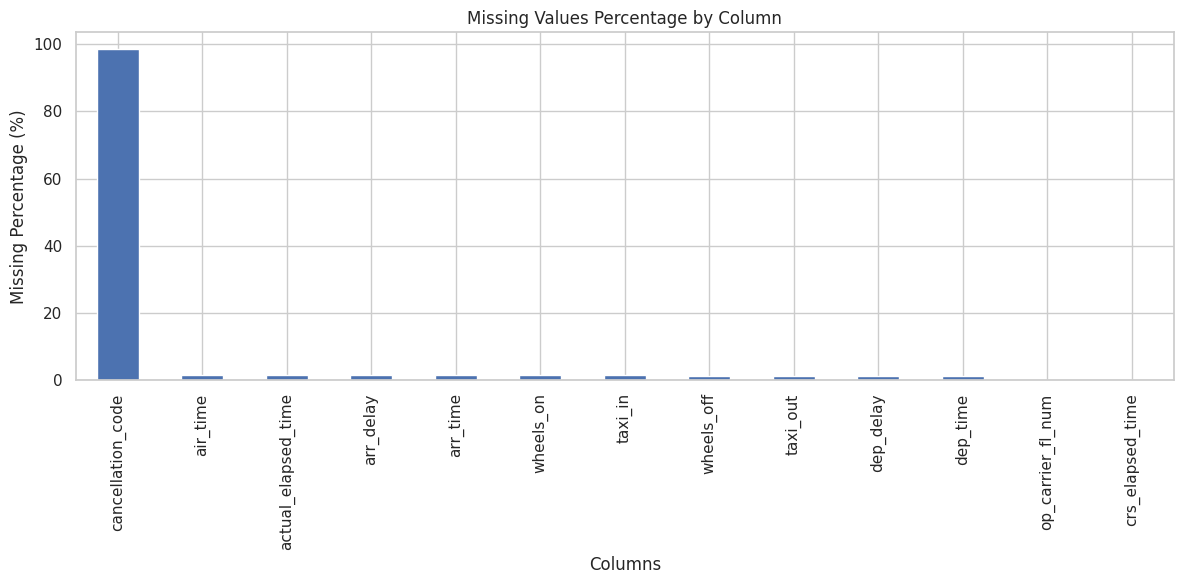

In [22]:
plt.figure(figsize=(12, 6))

missing_report["Missing Percentage"].plot(
    kind="bar"
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Columns")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [23]:
print("Cancelled Flight Counts:")
display(df["cancelled"].value_counts())

print("Diverted Flight Counts:")
display(df["diverted"].value_counts())

Cancelled Flight Counts:


,count
cancelled,
0,6982766
1,96315


Diverted Flight Counts:


,count
diverted,
0,7061582
1,17499


In [24]:
columns_to_check = [
    "dep_time",
    "dep_delay",
    "taxi_out",
    "wheels_off",
    "wheels_on",
    "taxi_in",
    "arr_time",
    "arr_delay",
    "actual_elapsed_time",
    "air_time"
]

missing_by_cancellation = df.groupby(
    "cancelled"
)[columns_to_check].apply(
    lambda x: x.isnull().sum()
)

print("Missing Values by Cancellation Status:")
display(missing_by_cancellation)

Missing Values by Cancellation Status:


,dep_time,dep_delay,taxi_out,wheels_off,wheels_on,taxi_in,arr_time,arr_delay,actual_elapsed_time,air_time
cancelled,,,,,,,,,,
0,0,0,0,0,1541,1541,1539,17499,17499,17499
1,92659,92970,95734,95734,96315,96315,96315,96315,96315,96315


### Missing Value Treatment Strategy

Not all missing values should be replaced with the mean or median.

In this dataset, some flight details are missing because flights were cancelled or diverted. Replacing these values with artificial numbers could affect the accuracy of the analysis.

Therefore:

* Missing cancellation codes are replaced with "Not Cancelled" when the flight was not cancelled.
* Missing departure and arrival information is retained when the actual information is unavailable.
* Median imputation will be applied within the later machine-learning preprocessing pipeline, using the training data.


In [36]:
df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
] = df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
].fillna("Not Cancelled")

print(
    "Missing cancellation codes after treatment:",
    df["cancellation_code"].isnull().sum()
)

Missing cancellation codes after treatment: 0


## 2. Duplicate and Invalid Value Analysis

Duplicate records can affect the accuracy of analysis. Invalid values, such as negative flight distances or negative travel durations, must also be checked before further processing.


In [26]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [27]:
numeric_check_columns = [
    "crs_elapsed_time",
    "distance",
    "taxi_out",
    "taxi_in",
    "air_time"
]

invalid_counts = {}

for column in numeric_check_columns:
    invalid_counts[column] = (
        df[column] < 0
    ).sum()

invalid_report = pd.DataFrame(
    list(invalid_counts.items()),
    columns=["Column", "Negative Value Count"]
)

display(invalid_report)

,Column,Negative Value Count
0,crs_elapsed_time,1
1,distance,0
2,taxi_out,0
3,taxi_in,0
4,air_time,0


In [28]:
invalid_crs = (
    df["crs_elapsed_time"] < 0
).sum()

print("Invalid CRS Elapsed Time Before:",
      invalid_crs)

df.loc[
    df["crs_elapsed_time"] < 0,
    "crs_elapsed_time"
] = np.nan

print("Invalid CRS Elapsed Time After:",
      (df["crs_elapsed_time"] < 0).sum())

Invalid CRS Elapsed Time Before: 1
Invalid CRS Elapsed Time After: 0


## 3. Outlier Detection Using IQR Method

Outliers are values that differ significantly from the majority of observations.

The Interquartile Range (IQR) method identifies outliers using the first quartile (Q1), third quartile (Q3) and interquartile range.

IQR = Q3 − Q1

Lower Bound = Q1 − 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR


In [29]:
iqr_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "crs_elapsed_time",
    "actual_elapsed_time",
    "air_time",
    "distance"
]

iqr_results = []

for column in iqr_columns:

    data = df[column].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (data < lower_bound) |
        (data > upper_bound)
    ).sum()

    percentage = (outliers / len(data)) * 100

    iqr_results.append([
        column,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        outliers,
        round(percentage, 2)
    ])

iqr_report = pd.DataFrame(
    iqr_results,
    columns=[
        "Column",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count",
        "Outlier Percentage"
    ]
)

display(iqr_report)

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,dep_delay,-6.0,9.0,15.0,-28.5,31.5,909066,13.01
1,arr_delay,-15.0,9.0,24.0,-51.0,45.0,670540,9.63
2,taxi_out,12.0,21.0,9.0,-1.5,34.5,355622,5.09
3,taxi_in,5.0,10.0,5.0,-2.5,17.5,466184,6.68
4,crs_elapsed_time,93.0,177.0,84.0,-33.0,303.0,360025,5.09
5,actual_elapsed_time,88.0,172.0,84.0,-38.0,298.0,341997,4.91
6,air_time,63.0,145.0,82.0,-60.0,268.0,349654,5.02
7,distance,399.0,1069.0,670.0,-606.0,2074.0,420064,5.93


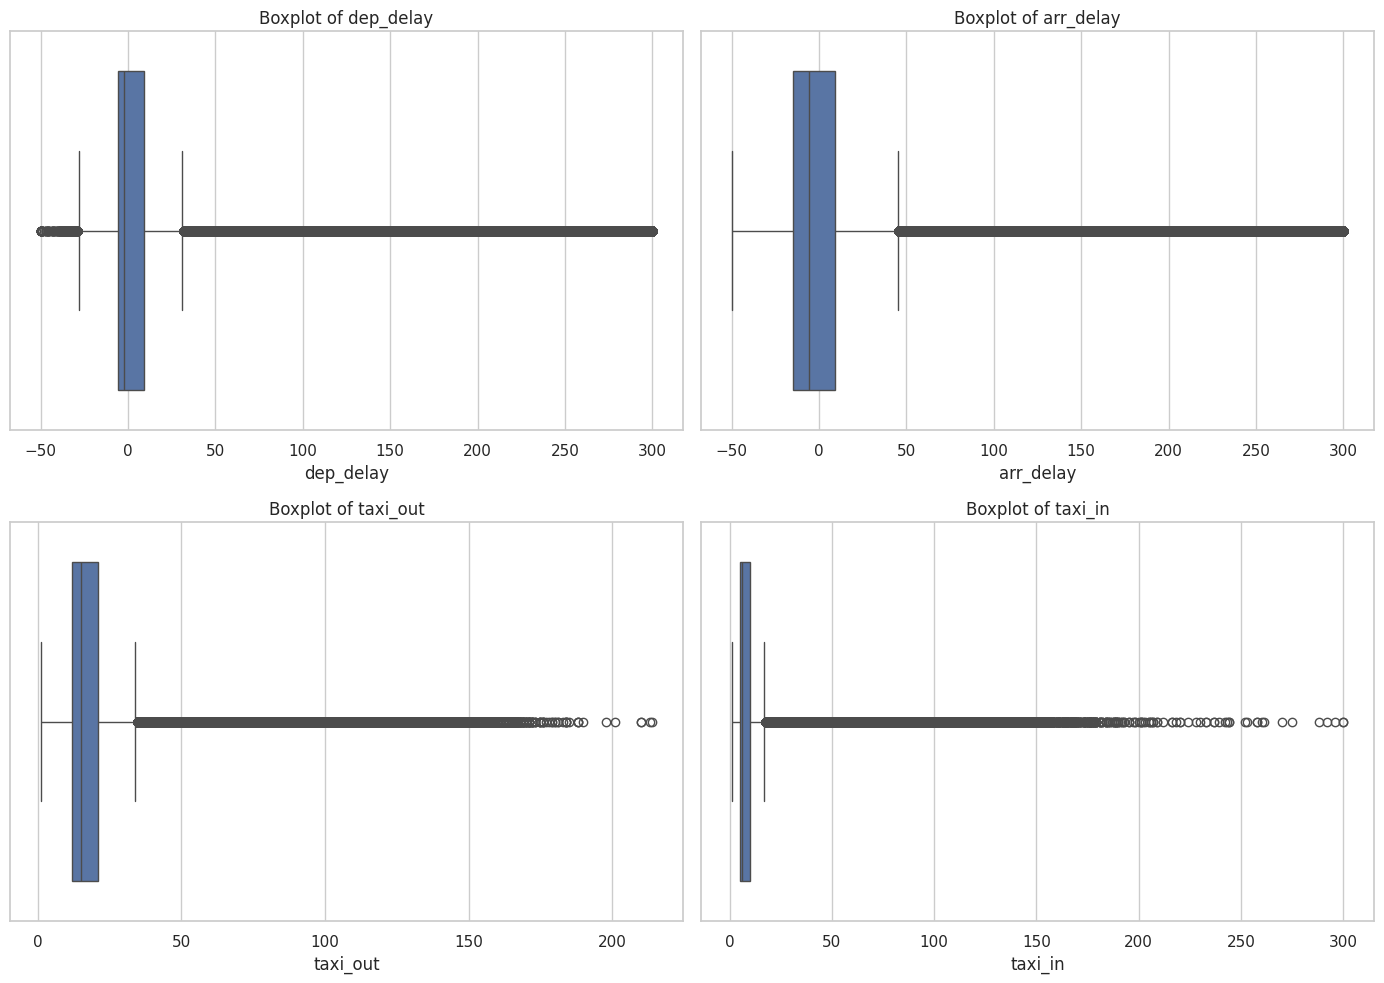

In [30]:
boxplot_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10)
)

for column, ax in zip(
    boxplot_columns,
    axes.flatten()
):

    sns.boxplot(
        x=df[column].dropna().clip(-50, 300),
        ax=ax
    )

    ax.set_title(
        "Boxplot of " + column
    )

plt.tight_layout()
plt.show()

## 4. Outlier Detection Using Z-Score

Z-score measures how far a data value is from the mean in terms of standard deviations.

Formula:

Z = (X − Mean) / Standard Deviation

Values with an absolute Z-score greater than 3 are considered potential outliers in this analysis.


In [31]:
zscore_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "crs_elapsed_time",
    "actual_elapsed_time",
    "air_time",
    "distance"
]

zscore_results = []

for column in zscore_columns:

    data = df[column].dropna()

    mean = data.mean()
    std = data.std()

    z_scores = ((data - mean) / std).abs()

    outlier_count = (z_scores > 3).sum()

    zscore_results.append([
        column,
        mean,
        std,
        outlier_count
    ])

zscore_report = pd.DataFrame(
    zscore_results,
    columns=[
        "Column",
        "Mean",
        "Standard Deviation",
        "Z-Score Outlier Count"
    ]
)

display(zscore_report)

,Column,Mean,Standard Deviation,Z-Score Outlier Count
0,dep_delay,12.677082,56.059970,100953
1,arr_delay,7.098245,57.991271,98400
2,taxi_out,17.904450,9.677410,124843
3,taxi_in,8.326030,6.844510,129604
4,crs_elapsed_time,146.766512,72.386837,100264
5,actual_elapsed_time,141.215140,72.307811,91593
6,air_time,114.999716,70.369553,91933
7,distance,833.906150,596.253594,61230


In [32]:
comparison = iqr_report[
    ["Column", "Outlier Count"]
].merge(
    zscore_report[
        ["Column", "Z-Score Outlier Count"]
    ],
    on="Column"
)

print("IQR and Z-Score Outlier Comparison:")
display(comparison)

IQR and Z-Score Outlier Comparison:


,Column,Outlier Count,Z-Score Outlier Count
0,dep_delay,909066,100953
1,arr_delay,670540,98400
2,taxi_out,355622,124843
3,taxi_in,466184,129604
4,crs_elapsed_time,360025,100264
5,actual_elapsed_time,341997,91593
6,air_time,349654,91933
7,distance,420064,61230


## 5. Automated Data Quality Report

An automated data quality report is generated to summarize the condition of the dataset after the initial cleaning operations. It includes data types, missing values and unique values for each column.


In [33]:
quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Count": df.isnull().sum().values,
    "Missing Percentage": (
        df.isnull().mean().values * 100
    ).round(2),
    "Unique Values": df.nunique(
        dropna=True
    ).values
})

display(quality_report)

,Column,Data Type,Missing Count,Missing Percentage,Unique Values
0,year,int64,0,0.00,1
1,month,int64,0,0.00,12
2,day_of_month,int64,0,0.00,31
3,day_of_week,int64,0,0.00,7
4,fl_date,object,0,0.00,366
5,op_unique_carrier,object,0,0.00,15
6,op_carrier_fl_num,float64,1,0.00,6862
7,origin,object,0,0.00,348
8,origin_city_name,object,0,0.00,342
9,origin_state_nm,object,0,0.00,52


In [34]:
quality_report.to_csv(
    "/content/data_quality_report_week3.csv",
    index=False
)

iqr_report.to_csv(
    "/content/iqr_outlier_report.csv",
    index=False
)

zscore_report.to_csv(
    "/content/zscore_outlier_report.csv",
    index=False
)

print("All Week 3 reports saved successfully!")

All Week 3 reports saved successfully!


In [35]:
print("WEEK 3 – FINAL DATA CLEANING SUMMARY")

print("-----------------------------------")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("Duplicate Records:", df.duplicated().sum())

print(
    "Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Negative CRS Elapsed Time:",
    (df["crs_elapsed_time"] < 0).sum()
)

print("-----------------------------------")
print("Week 3 cleaning checks completed!")

WEEK 3 – FINAL DATA CLEANING SUMMARY
-----------------------------------
Total Rows: 7079081
Total Columns: 35
Duplicate Records: 0
Missing Values: 1012108
Negative CRS Elapsed Time: 0
-----------------------------------
Week 3 cleaning checks completed!


## Conclusion

In Week 3, the Flight Data 2024 dataset was examined for missing values, duplicate records and invalid entries. A suitable strategy was followed to handle missing cancellation codes while retaining unavailable flight information that could have a meaningful reason.

Outliers were identified using the IQR method, Boxplots and Z-score. An automated Data Quality Report was also generated.

These steps helped us understand the quality of the dataset and prepare it for further exploratory data analysis.


# WEEK 4 – EDA DEEP DIVE

## Objective

To perform Exploratory Data Analysis (EDA) on the Flight Data 2024 dataset using univariate and bivariate analysis. To understand data distributions, identify patterns and examine relationships between flight delays and other variables.

## Introduction

Exploratory Data Analysis (EDA) helps us understand patterns, trends and relationships within a dataset before applying further analytical techniques.

In this week, we analyse flight delays, examine the distribution of important numerical variables and compare delays across different months, airlines and days of the week. Graphs and statistical summaries are used to understand the behaviour of the data.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import glob
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [38]:
dataset_path = kagglehub.dataset_download(
    "hrishitpatil/flight-data-2024"
)

csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

if not csv_candidates:
    raise FileNotFoundError("Dataset file not found!")

file_path = csv_candidates[0]

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset loaded successfully!
Dataset Shape: (7079081, 35)


In [39]:
analysis_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "air_time",
    "distance"
]

print("DESCRIPTIVE STATISTICS")

display(
    df[analysis_columns].describe().T.round(2)
)

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
dep_delay,6986111.0,12.68,56.06,-96.0,-6.0,-2.0,9.0,3777.0
arr_delay,6965267.0,7.10,57.99,-126.0,-15.0,-6.0,9.0,3803.0
taxi_out,6983347.0,17.90,9.68,1.0,12.0,15.0,21.0,214.0
taxi_in,6981225.0,8.33,6.84,1.0,5.0,6.0,10.0,444.0
air_time,6965267.0,115.00,70.37,5.0,63.0,98.0,145.0,723.0
distance,7079081.0,833.91,596.25,11.0,399.0,680.0,1069.0,5095.0


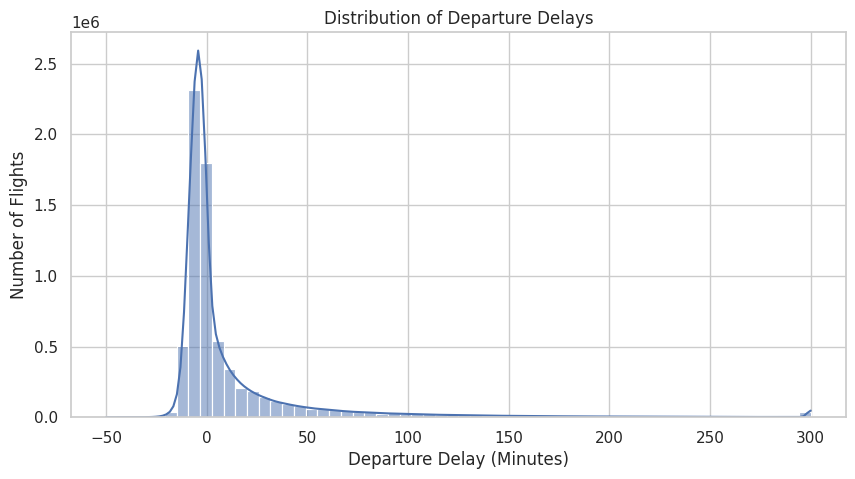

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["dep_delay"].dropna().clip(-50, 300),
    bins=60,
    kde=True
)

plt.title("Distribution of Departure Delays")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.show()

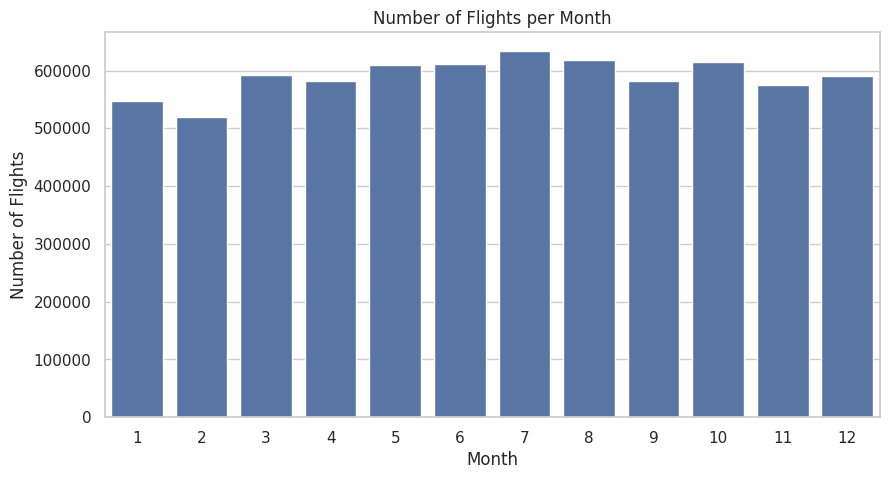

In [41]:
monthly_flights = df["month"].value_counts().sort_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=monthly_flights.index,
    y=monthly_flights.values
)

plt.title("Number of Flights per Month")
plt.xlabel("Month")
plt.ylabel("Number of Flights")
plt.show()

Monthly Average Departure and Arrival Delays:


,dep_delay,arr_delay
month,,
1,15.70,10.35
2,7.46,0.59
3,12.45,6.50
4,10.81,5.36
5,18.09,14.05
6,16.95,11.81
7,22.35,18.09
8,15.31,10.59
9,6.65,1.00


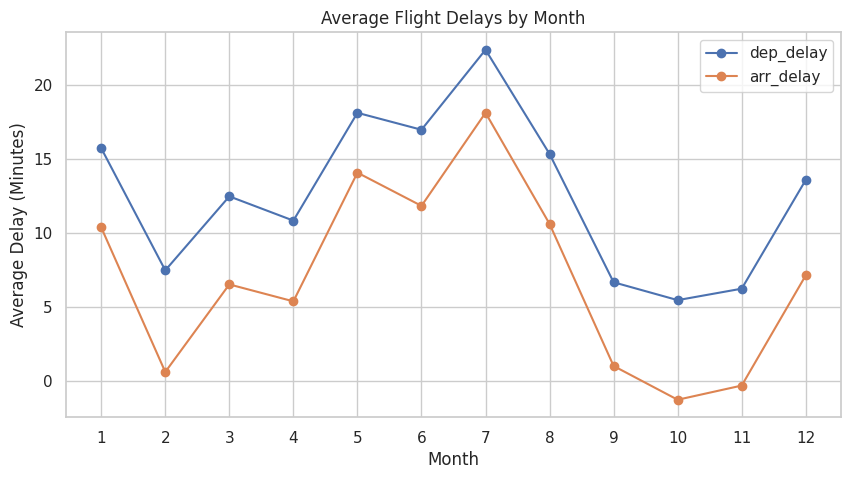

In [42]:
monthly_delay = df.groupby("month")[
    ["dep_delay", "arr_delay"]
].mean()

print("Monthly Average Departure and Arrival Delays:")
display(monthly_delay.round(2))

monthly_delay.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Average Flight Delays by Month")
plt.xlabel("Month")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

Average Delay by Airline:


,dep_delay,arr_delay
op_unique_carrier,,
AA,20.70,15.31
F9,19.00,15.25
B6,17.46,10.74
OH,13.94,10.03
G4,14.05,9.71
NK,14.96,8.42
OO,11.28,7.36
MQ,10.18,6.46
UA,11.96,5.74


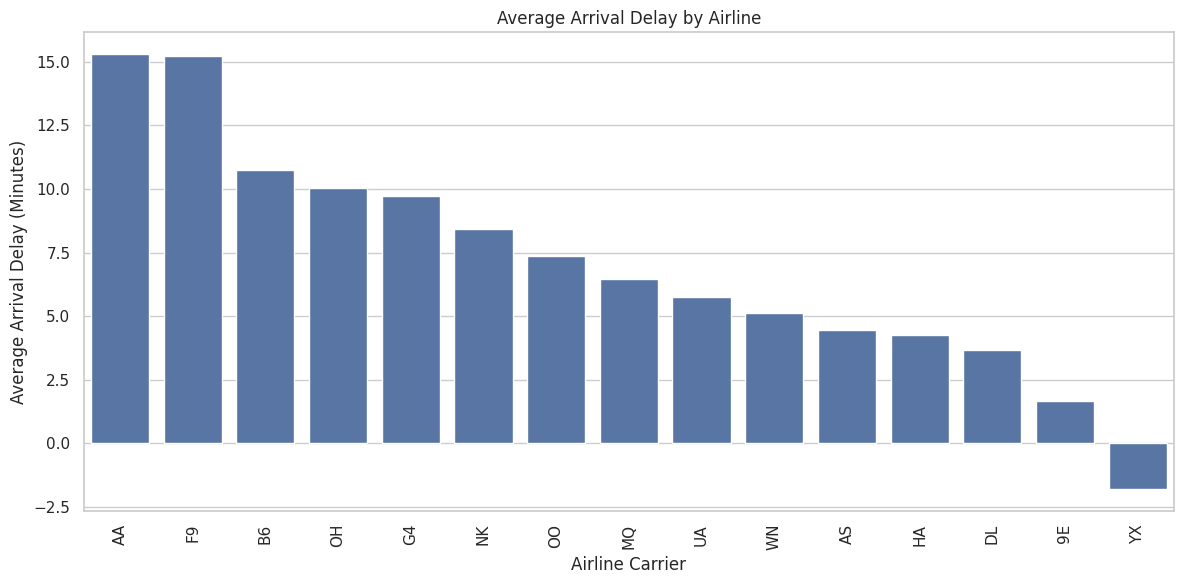

In [43]:
carrier_delay = df.groupby(
    "op_unique_carrier"
)[["dep_delay", "arr_delay"]].mean()

carrier_delay = carrier_delay.sort_values(
    by="arr_delay",
    ascending=False
)

print("Average Delay by Airline:")
display(carrier_delay.round(2))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=carrier_delay.reset_index(),
    x="op_unique_carrier",
    y="arr_delay"
)

plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline Carrier")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Average Delay by Day of Week:


,dep_delay,arr_delay
day_of_week,,
1,12.73,7.03
2,10.46,4.39
3,10.42,4.83
4,13.16,8.18
5,14.66,9.61
6,12.59,6.45
7,14.39,8.77


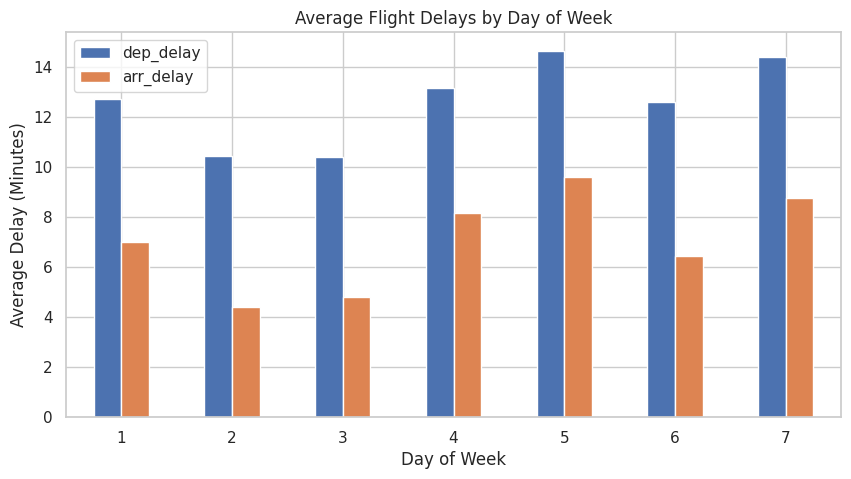

In [44]:
day_delay = df.groupby("day_of_week")[
    ["dep_delay", "arr_delay"]
].mean()

print("Average Delay by Day of Week:")
display(day_delay.round(2))

day_delay.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Flight Delays by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=0)
plt.show()

Correlation between Departure and Arrival Delay:


,dep_delay,arr_delay
dep_delay,1.000,0.971
arr_delay,0.971,1.000


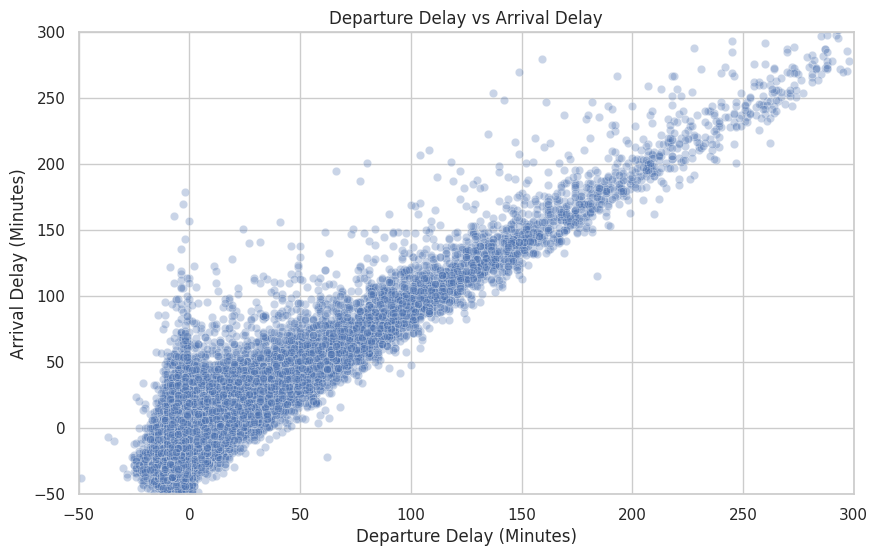

In [45]:
correlation = df[
    ["dep_delay", "arr_delay"]
].corr()

print("Correlation between Departure and Arrival Delay:")
display(correlation.round(3))

sample_data = df[
    ["dep_delay", "arr_delay"]
].dropna().sample(
    n=50000,
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_data,
    x="dep_delay",
    y="arr_delay",
    alpha=0.3
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Arrival Delay (Minutes)")
plt.xlim(-50, 300)
plt.ylim(-50, 300)
plt.show()

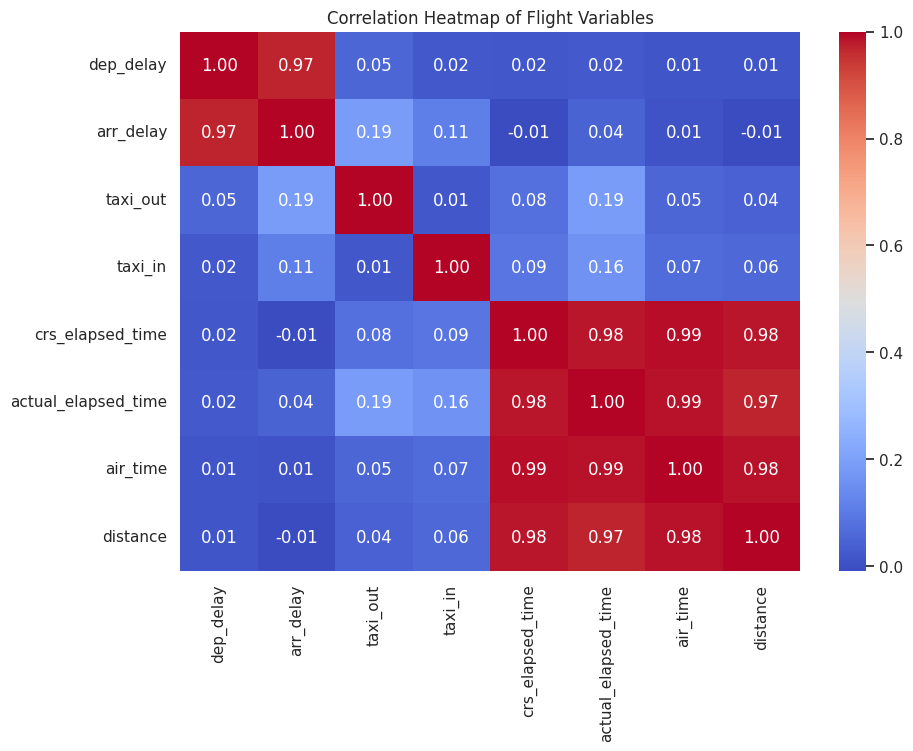

In [46]:
correlation_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "crs_elapsed_time",
    "actual_elapsed_time",
    "air_time",
    "distance"
]

correlation_matrix = df[
    correlation_columns
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Flight Variables")
plt.show()

In [47]:
monthly_delay.to_csv(
    "/content/monthly_delay_report.csv"
)

carrier_delay.to_csv(
    "/content/carrier_delay_report.csv"
)

day_delay.to_csv(
    "/content/day_of_week_delay_report.csv"
)

correlation_matrix.to_csv(
    "/content/correlation_matrix_week4.csv"
)

print("All Week 4 EDA reports saved successfully!")

All Week 4 EDA reports saved successfully!


In [48]:
print("WEEK 4 – EDA SUMMARY")
print("-------------------------------")

print("Total Flights:", len(df))

print(
    "Average Departure Delay:",
    round(df["dep_delay"].mean(), 2),
    "minutes"
)

print(
    "Average Arrival Delay:",
    round(df["arr_delay"].mean(), 2),
    "minutes"
)

print(
    "Departure and Arrival Delay Correlation:",
    round(
        df["dep_delay"].corr(df["arr_delay"]),
        3
    )
)

print("-------------------------------")
print("Week 4 EDA completed successfully!")

WEEK 4 – EDA SUMMARY
-------------------------------
Total Flights: 7079081
Average Departure Delay: 12.68 minutes
Average Arrival Delay: 7.1 minutes
Departure and Arrival Delay Correlation: 0.971
-------------------------------
Week 4 EDA completed successfully!


## Conclusion

In Week 4, Exploratory Data Analysis was performed on the Flight Data 2024 dataset using univariate and bivariate analysis.

The distributions of departure delays, arrival delays and other flight-related variables were examined using histograms and statistical summaries. Monthly flight patterns and average delays across airlines and days of the week were also analysed.

Scatter plots and correlation analysis were used to study relationships between flight variables. These visualisations helped identify important patterns and provided a better understanding of flight delay behaviour.

# WEEK 5 – MID-REVIEW: DATA AUDIT

## Objective

To perform a final audit of the Flight Data 2024 dataset by reviewing the cleaning results, examining important statistical findings and preparing the dataset for further analysis.

## Introduction

In this week, we review the work completed during data cleaning and exploratory data analysis. We examine the dataset dimensions, missing values, duplicate records and invalid values. Important statistical findings related to flight delays are also summarized.

This audit helps us evaluate the quality of the dataset and identify the key findings obtained so far.

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import glob
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [50]:
dataset_path = kagglehub.dataset_download(
    "hrishitpatil/flight-data-2024"
)

csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

if not csv_candidates:
    raise FileNotFoundError("Dataset file not found!")

file_path = csv_candidates[0]

df = pd.read_csv(file_path, low_memory=False)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset loaded successfully!
Dataset Shape: (7079081, 35)


In [51]:
# Replace missing cancellation codes for non-cancelled flights
df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
] = df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
].fillna("Not Cancelled")

# Correct invalid negative CRS elapsed time
df.loc[
    df["crs_elapsed_time"] < 0,
    "crs_elapsed_time"
] = np.nan

print("Cleaning treatments applied successfully!")

print(
    "Missing cancellation codes after treatment:",
    df["cancellation_code"].isnull().sum()
)

Cleaning treatments applied successfully!
Missing cancellation codes after treatment: 0


In [52]:
print("FINAL DATASET DIMENSIONS")
print("------------------------")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Total Records:", len(df))

FINAL DATASET DIMENSIONS
------------------------
Total Rows: 7079081
Total Columns: 35
Total Records: 7079081


In [53]:
missing_audit = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_audit = missing_audit[
    missing_audit["Missing Count"] > 0
].sort_values(
    by="Missing Count",
    ascending=False
)

print("MISSING VALUE AUDIT")
display(missing_audit)

MISSING VALUE AUDIT


,Missing Count,Missing Percentage
air_time,113814,1.61
arr_delay,113814,1.61
actual_elapsed_time,113814,1.61
wheels_on,97856,1.38
taxi_in,97856,1.38
arr_time,97854,1.38
wheels_off,95734,1.35
taxi_out,95734,1.35
dep_delay,92970,1.31
dep_time,92659,1.31


In [54]:
print("DUPLICATE RECORDS:", df.duplicated().sum())

invalid_columns = [
    "crs_elapsed_time",
    "distance",
    "taxi_out",
    "taxi_in",
    "air_time"
]

print("\nNEGATIVE VALUE CHECK")

for column in invalid_columns:
    print(
        column,
        ":",
        (df[column] < 0).sum()
    )

DUPLICATE RECORDS: 0

NEGATIVE VALUE CHECK
crs_elapsed_time : 0
distance : 0
taxi_out : 0
taxi_in : 0
air_time : 0


In [55]:
important_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "air_time",
    "distance"
]

print("STATISTICAL SUMMARY")
display(
    df[important_columns].describe().T.round(2)
)

STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
dep_delay,6986111.0,12.68,56.06,-96.0,-6.0,-2.0,9.0,3777.0
arr_delay,6965267.0,7.10,57.99,-126.0,-15.0,-6.0,9.0,3803.0
taxi_out,6983347.0,17.90,9.68,1.0,12.0,15.0,21.0,214.0
taxi_in,6981225.0,8.33,6.84,1.0,5.0,6.0,10.0,444.0
air_time,6965267.0,115.00,70.37,5.0,63.0,98.0,145.0,723.0
distance,7079081.0,833.91,596.25,11.0,399.0,680.0,1069.0,5095.0


In [56]:
print("FLIGHT DELAY FINDINGS")
print("---------------------")

print(
    "Average Departure Delay:",
    round(df["dep_delay"].mean(), 2),
    "minutes"
)

print(
    "Average Arrival Delay:",
    round(df["arr_delay"].mean(), 2),
    "minutes"
)

print(
    "Maximum Departure Delay:",
    df["dep_delay"].max(),
    "minutes"
)

print(
    "Maximum Arrival Delay:",
    df["arr_delay"].max(),
    "minutes"
)

print(
    "Correlation between Departure and Arrival Delay:",
    round(df["dep_delay"].corr(df["arr_delay"]), 3)
)

FLIGHT DELAY FINDINGS
---------------------
Average Departure Delay: 12.68 minutes
Average Arrival Delay: 7.1 minutes
Maximum Departure Delay: 3777.0 minutes
Maximum Arrival Delay: 3803.0 minutes
Correlation between Departure and Arrival Delay: 0.971


In [57]:
print("FLIGHT STATUS SUMMARY")

print("\nCancelled Flights:")
display(df["cancelled"].value_counts())

print("\nDiverted Flights:")
display(df["diverted"].value_counts())

FLIGHT STATUS SUMMARY

Cancelled Flights:


,count
cancelled,
0,6982766
1,96315



Diverted Flights:


,count
diverted,
0,7061582
1,17499


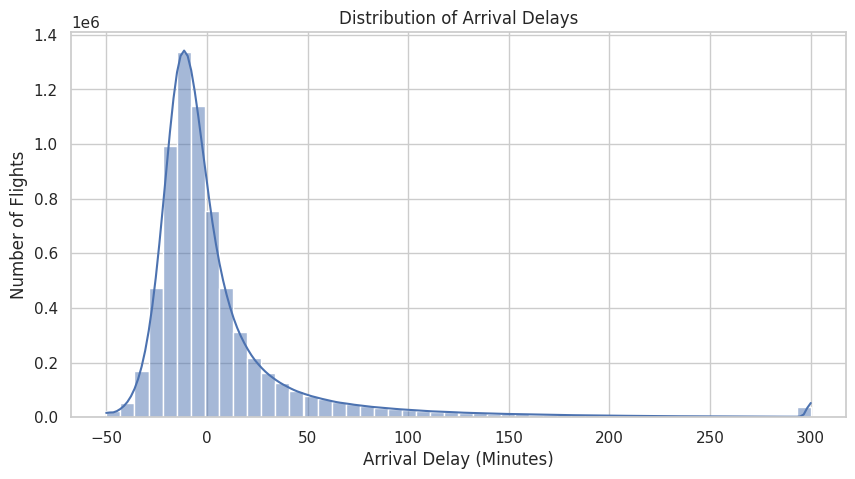

In [58]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["arr_delay"].dropna().clip(-50, 300),
    bins=50,
    kde=True
)

plt.title("Distribution of Arrival Delays")
plt.xlabel("Arrival Delay (Minutes)")
plt.ylabel("Number of Flights")
plt.show()

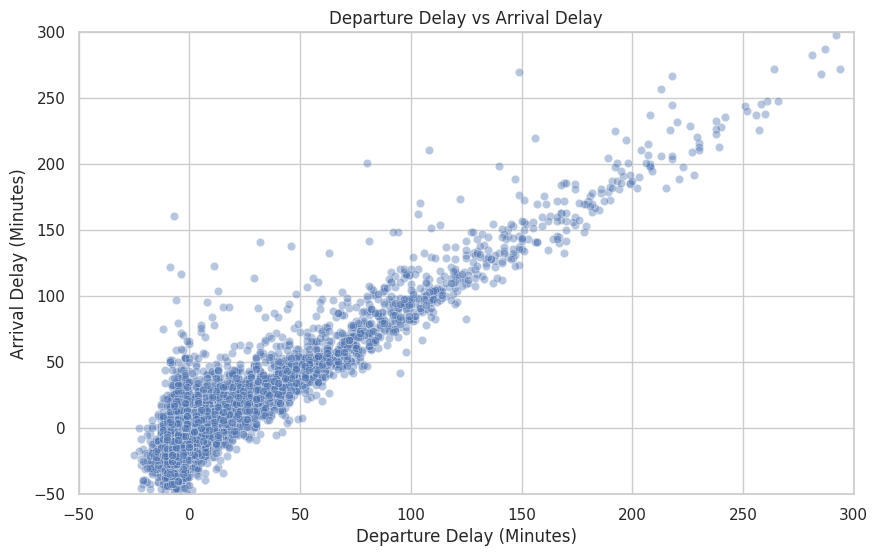

In [59]:
sample_data = df[
    ["dep_delay", "arr_delay"]
].dropna().sample(
    n=10000,
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_data,
    x="dep_delay",
    y="arr_delay",
    alpha=0.4
)

plt.title("Departure Delay vs Arrival Delay")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Arrival Delay (Minutes)")
plt.xlim(-50, 300)
plt.ylim(-50, 300)

plt.show()

In [60]:
audit_summary = pd.DataFrame({
    "Audit Category": [
        "Total Records",
        "Total Columns",
        "Duplicate Records",
        "Total Missing Values",
        "Cancelled Flights",
        "Diverted Flights",
        "Average Departure Delay",
        "Average Arrival Delay",
        "Delay Correlation"
    ],
    "Result": [
        df.shape[0],
        df.shape[1],
        df.duplicated().sum(),
        df.isnull().sum().sum(),
        (df["cancelled"] == 1).sum(),
        (df["diverted"] == 1).sum(),
        round(df["dep_delay"].mean(), 2),
        round(df["arr_delay"].mean(), 2),
        round(df["dep_delay"].corr(df["arr_delay"]), 3)
    ]
})

print("WEEK 5 – MID-REVIEW DATA AUDIT REPORT")
display(audit_summary)

audit_summary.to_csv(
    "/content/week5_data_audit_report.csv",
    index=False
)

print("Data audit report saved successfully!")

WEEK 5 – MID-REVIEW DATA AUDIT REPORT


,Audit Category,Result
0,Total Records,7079081.000
1,Total Columns,35.000
2,Duplicate Records,0.000
3,Total Missing Values,1012108.000
4,Cancelled Flights,96315.000
5,Diverted Flights,17499.000
6,Average Departure Delay,12.680
7,Average Arrival Delay,7.100
8,Delay Correlation,0.971


Data audit report saved successfully!


## Conclusion

In Week 5, a mid-review data audit was performed on the Flight Data 2024 dataset. The dataset was reviewed for missing values, duplicate records and invalid values. Important statistical findings related to departure delays, arrival delays, cancellations and diversions were also examined.

The analysis showed a strong positive correlation between departure delay and arrival delay. The audit helped summarize the progress made during the first five weeks and provided a foundation for the upcoming feature engineering and advanced analysis stages.

WEEK 6 – FEATURE ENGINEERING
## Objective

To create new meaningful features from the Flight Data 2024 dataset, examine the distribution of numerical variables, reduce skewness using transformation techniques, and apply encoding and scaling methods to prepare the data for further analysis.


## Introduction

In this week, feature engineering is performed to improve the usefulness of the Flight Data 2024 dataset. New features are created using existing columns, such as flight routes, weekends and departure delay categories.

The distribution of numerical variables is also examined to identify skewness. Transformation techniques are applied to reduce skewness, while encoding and scaling methods are demonstrated to prepare numerical and categorical features for future analysis.


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import glob
import warnings

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    PowerTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [62]:
dataset_path = kagglehub.dataset_download(
    "hrishitpatil/flight-data-2024"
)

csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

if not csv_candidates:
    raise FileNotFoundError("Dataset file not found!")

file_path = csv_candidates[0]

df = pd.read_csv(file_path, low_memory=False)

# Apply the cleaning treatments from previous weeks
df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
] = df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
].fillna("Not Cancelled")

df.loc[
    df["crs_elapsed_time"] < 0,
    "crs_elapsed_time"
] = np.nan

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset loaded successfully!
Dataset Shape: (7079081, 35)


In [63]:
# Create flight route
df["route"] = (
    df["origin"].astype("string")
    + "-"
    + df["dest"].astype("string")
)

# Create weekend indicator
df["is_weekend"] = (
    df["day_of_week"].isin([6, 7])
).astype("int8")

# Create departure delay categories
df["departure_delay_category"] = pd.cut(
    df["dep_delay"],
    bins=[-np.inf, 0, 15, 60, np.inf],
    labels=[
        "On time/early",
        "Small delay",
        "Moderate delay",
        "High delay"
    ]
)

print("New features created successfully!")

display(
    df[
        [
            "origin",
            "dest",
            "route",
            "day_of_week",
            "is_weekend",
            "dep_delay",
            "departure_delay_category"
        ]
    ].head()
)

New features created successfully!


,origin,dest,route,day_of_week,is_weekend,dep_delay,departure_delay_category
0,JFK,DTW,JFK-DTW,1,0,-5.0,On time/early
1,MSP,CLE,MSP-CLE,1,0,-14.0,On time/early
2,JFK,RIC,JFK-RIC,1,0,-4.0,On time/early
3,RIC,JFK,RIC-JFK,1,0,-7.0,On time/early
4,DTW,MKE,DTW-MKE,1,0,-5.0,On time/early


In [64]:
print("FEATURE ENGINEERING SUMMARY")
print("----------------------------")

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nWeekend Flight Count:")
display(df["is_weekend"].value_counts())

print("\nDeparture Delay Categories:")
display(df["departure_delay_category"].value_counts())

FEATURE ENGINEERING SUMMARY
----------------------------
Total Rows: 7079081
Total Columns: 38

Weekend Flight Count:


,count
is_weekend,
0,5120586
1,1958495



Departure Delay Categories:


,count
departure_delay_category,
On time/early,4380129
Small delay,1208898
Moderate delay,888857
High delay,508227


In [65]:
stats_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "crs_elapsed_time",
    "actual_elapsed_time",
    "air_time",
    "distance"
]

distribution_stats = pd.DataFrame({
    "Skewness": df[stats_columns].skew(),
    "Kurtosis": df[stats_columns].kurt()
})

print("SKEWNESS AND KURTOSIS")
display(distribution_stats.round(3))

SKEWNESS AND KURTOSIS


,Skewness,Kurtosis
dep_delay,11.059,225.374
arr_delay,10.083,198.139
taxi_out,3.489,23.602
taxi_in,5.069,60.245
crs_elapsed_time,1.387,2.389
actual_elapsed_time,1.368,2.352
air_time,1.403,2.449
distance,1.457,2.690


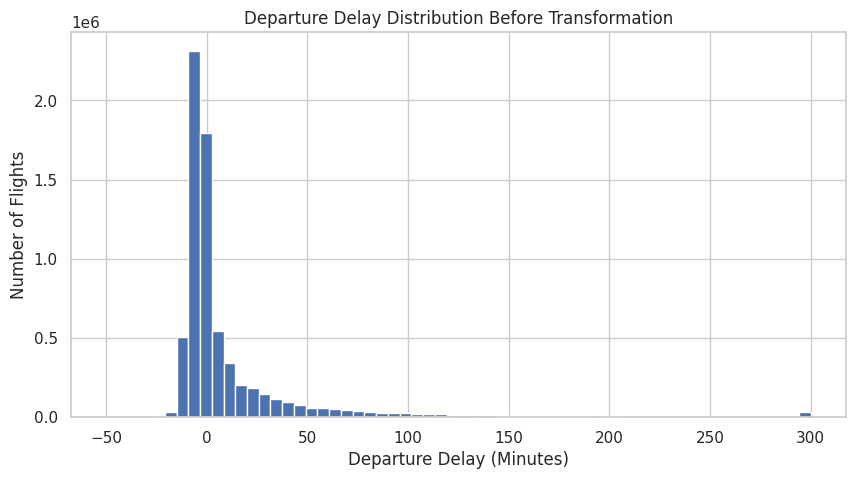

In [66]:
plt.figure(figsize=(10, 5))

df["dep_delay"].dropna().clip(-50, 300).hist(bins=60)

plt.title("Departure Delay Distribution Before Transformation")
plt.xlabel("Departure Delay (Minutes)")
plt.ylabel("Number of Flights")

plt.show()

In [67]:
transform_columns = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "air_time",
    "distance"
]

transform_sample = df[transform_columns].dropna()

transform_sample = transform_sample.sample(
    n=min(100000, len(transform_sample)),
    random_state=42
)

power_transformer = PowerTransformer(
    method="yeo-johnson"
)

transformed_values = power_transformer.fit_transform(
    transform_sample
)

transformed_df = pd.DataFrame(
    transformed_values,
    columns=transform_columns
)

skew_comparison = pd.DataFrame({
    "Before Transformation": transform_sample.skew(),
    "After Transformation": transformed_df.skew()
})

print("SKEWNESS BEFORE AND AFTER TRANSFORMATION")
display(skew_comparison.round(3))

SKEWNESS BEFORE AND AFTER TRANSFORMATION


,Before Transformation,After Transformation
dep_delay,12.594,-0.257
arr_delay,11.380,0.109
taxi_out,3.514,-0.022
taxi_in,5.145,0.014
air_time,1.412,-0.003
distance,1.464,-0.015


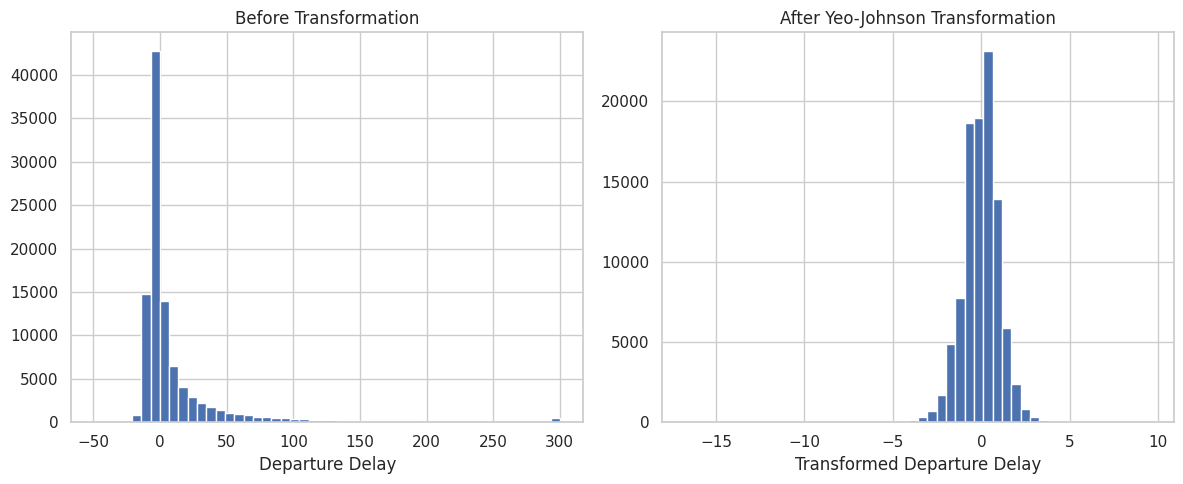

In [68]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.hist(
    transform_sample["dep_delay"].clip(-50, 300),
    bins=50
)

plt.title("Before Transformation")
plt.xlabel("Departure Delay")

plt.subplot(1, 2, 2)

plt.hist(
    transformed_df["dep_delay"],
    bins=50
)

plt.title("After Yeo-Johnson Transformation")
plt.xlabel("Transformed Departure Delay")

plt.tight_layout()
plt.show()

In [69]:
from sklearn.pipeline import Pipeline

# Select sample data
encoding_sample = df[
    [
        "dep_delay",
        "arr_delay",
        "taxi_out",
        "taxi_in",
        "op_unique_carrier",
        "month"
    ]
].sample(
    n=100000,
    random_state=42
).copy()

numeric_features = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in"
]

categorical_features = [
    "op_unique_carrier",
    "month"
]

# Numerical processing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical processing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both processes
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

prepared_data = preprocessor.fit_transform(encoding_sample)

print("ENCODING AND SCALING COMPLETED")
print("Original Sample Shape:", encoding_sample.shape)
print("Prepared Data Shape:", prepared_data.shape)

ENCODING AND SCALING COMPLETED
Original Sample Shape: (100000, 6)
Prepared Data Shape: (100000, 31)


In [70]:
scaled_data = pd.DataFrame(
    prepared_data[:, :len(numeric_features)],
    columns=numeric_features
)

print("SCALED NUMERICAL FEATURES")
display(scaled_data.head())

print("\nMean of Scaled Features:")
display(scaled_data.mean().round(3))

print("\nStandard Deviation of Scaled Features:")
display(scaled_data.std().round(3))

SCALED NUMERICAL FEATURES


,dep_delay,arr_delay,taxi_out,taxi_in
0,-0.288151,-0.301965,0.329444,-0.632102
1,-0.306836,-0.428007,-0.402087,-0.338638
2,-0.381573,-0.428007,-0.506591,-0.045174
3,-0.157361,-0.103899,-1.029113,-0.338638
4,-0.362889,-0.139911,-0.193078,-0.632102



Mean of Scaled Features:


,0
dep_delay,-0.0
arr_delay,0.0
taxi_out,-0.0
taxi_in,-0.0



Standard Deviation of Scaled Features:


,0
dep_delay,1.0
arr_delay,1.0
taxi_out,1.0
taxi_in,1.0


In [71]:
# Save skewness comparison
skew_comparison.to_csv(
    "/content/week6_skewness_comparison.csv"
)

# Save feature engineering sample
df[
    [
        "route",
        "is_weekend",
        "departure_delay_category"
    ]
].head(1000).to_csv(
    "/content/week6_feature_sample.csv",
    index=False
)

print("Week 6 reports saved successfully!")

Week 6 reports saved successfully!


In [72]:
print("WEEK 6 – FEATURE ENGINEERING SUMMARY")
print("------------------------------------")

print("Total Rows:", df.shape[0])
print("Original Columns: 35")
print("New Features Created: 3")
print("Final Columns:", df.shape[1])

print("\nNew Features:")
print("1. route")
print("2. is_weekend")
print("3. departure_delay_category")

print("\nTransformation: Yeo-Johnson")
print("Scaling Method: StandardScaler")
print("Encoding Method: One-Hot Encoding")

print("\nWeek 6 feature engineering completed successfully!")

WEEK 6 – FEATURE ENGINEERING SUMMARY
------------------------------------
Total Rows: 7079081
Original Columns: 35
New Features Created: 3
Final Columns: 38

New Features:
1. route
2. is_weekend
3. departure_delay_category

Transformation: Yeo-Johnson
Scaling Method: StandardScaler
Encoding Method: One-Hot Encoding

Week 6 feature engineering completed successfully!


## Conclusion

In Week 6, feature engineering was performed on the Flight Data 2024 dataset. Three new features were created to identify flight routes, weekend flights and departure delay categories.

The skewness of numerical variables was examined, and the Yeo-Johnson transformation was applied to a sample of the data. Standard scaling and One-Hot Encoding were also performed to prepare numerical and categorical features for further analysis.

These steps improved the structure and usefulness of the dataset and prepared it for the upcoming dimensionality reduction and feature selection stages.


## Objective

To perform feature selection and dimensionality reduction on the Flight Data 2024 dataset using Principal Component Analysis (PCA). The aim is to reduce the number of features while retaining important information and visualizing the variance explained by the selected principal components.


## Introduction

In this week, dimensionality reduction techniques are applied to the flight dataset. Feature selection is performed to identify important numerical variables, and Principal Component Analysis (PCA) is used to transform the selected features into a smaller set of principal components.

The explained variance is examined to understand how much information is retained after dimensionality reduction. Two-dimensional and three-dimensional visualizations are also created to understand the distribution of the principal components.


In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import glob
import warnings

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [75]:
dataset_path = kagglehub.dataset_download(
    "hrishitpatil/flight-data-2024"
)

csv_candidates = glob.glob(
    os.path.join(dataset_path, "**", "flight_data_2024.csv"),
    recursive=True
)

if not csv_candidates:
    raise FileNotFoundError("Dataset file not found!")

file_path = csv_candidates[0]

df = pd.read_csv(file_path, low_memory=False)

# Apply cleaning treatments
df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
] = df.loc[
    df["cancelled"] == 0,
    "cancellation_code"
].fillna("Not Cancelled")

df.loc[
    df["crs_elapsed_time"] < 0,
    "crs_elapsed_time"
] = np.nan

# Recreate Week 6 features
df["route"] = (
    df["origin"].astype("string")
    + "-"
    + df["dest"].astype("string")
)

df["is_weekend"] = (
    df["day_of_week"].isin([6, 7])
).astype("int8")

df["departure_delay_category"] = pd.cut(
    df["dep_delay"],
    bins=[-np.inf, 0, 15, 60, np.inf],
    labels=[
        "On time/early",
        "Small delay",
        "Moderate delay",
        "High delay"
    ]
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset loaded successfully!
Dataset Shape: (7079081, 38)


In [76]:
selected_features = [
    "dep_delay",
    "arr_delay",
    "taxi_out",
    "taxi_in",
    "crs_elapsed_time",
    "actual_elapsed_time",
    "air_time",
    "distance"
]

feature_data = df[selected_features].sample(
    n=100000,
    random_state=42
)

print("SELECTED FEATURES")
display(feature_data.head())

print("Number of Selected Features:", len(selected_features))

SELECTED FEATURES


,dep_delay,arr_delay,taxi_out,taxi_in,crs_elapsed_time,actual_elapsed_time,air_time,distance
1996999,-3.0,-10.0,21.0,4.0,151.0,144.0,119.0,835.0
848,-4.0,-17.0,14.0,6.0,286.0,273.0,253.0,1773.0
6697762,-8.0,-17.0,13.0,8.0,59.0,50.0,29.0,106.0
1810495,4.0,1.0,8.0,6.0,180.0,177.0,163.0,1099.0
828505,-7.0,-1.0,16.0,4.0,90.0,96.0,76.0,399.0


Number of Selected Features: 8


In [77]:
imputer = SimpleImputer(strategy="median")

imputed_data = imputer.fit_transform(feature_data)

imputed_df = pd.DataFrame(
    imputed_data,
    columns=selected_features
)

print("Missing values handled successfully!")
print("Missing Values After Imputation:",
      imputed_df.isnull().sum().sum())

Missing values handled successfully!
Missing Values After Imputation: 0


In [78]:
selector = VarianceThreshold(threshold=0)

selected_data = selector.fit_transform(imputed_df)

selected_feature_names = imputed_df.columns[
    selector.get_support()
]

selected_df = pd.DataFrame(
    selected_data,
    columns=selected_feature_names
)

print("FEATURE SELECTION RESULTS")
print("-------------------------")

print("Features Before Selection:", len(selected_features))
print("Features After Selection:", len(selected_feature_names))

print("\nSelected Features:")
print(list(selected_feature_names))

FEATURE SELECTION RESULTS
-------------------------
Features Before Selection: 8
Features After Selection: 8

Selected Features:
['dep_delay', 'arr_delay', 'taxi_out', 'taxi_in', 'crs_elapsed_time', 'actual_elapsed_time', 'air_time', 'distance']


In [79]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(selected_df)

print("Standardization completed successfully!")
print("Scaled Data Shape:", scaled_data.shape)

Standardization completed successfully!
Scaled Data Shape: (100000, 8)


In [80]:
pca = PCA(
    n_components=0.90,
    svd_solver="full"
)

pca_data = pca.fit_transform(scaled_data)

print("PCA COMPLETED SUCCESSFULLY")
print("--------------------------")

print("Original Number of Features:", scaled_data.shape[1])
print("Number of Principal Components:", pca.n_components_)
print(
    "Total Explained Variance:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

PCA COMPLETED SUCCESSFULLY
--------------------------
Original Number of Features: 8
Number of Principal Components: 4
Total Explained Variance: 99.11 %


In [81]:
explained_variance = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))
    ],
    "Explained Variance": pca.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(
        pca.explained_variance_ratio_
    )
})

print("EXPLAINED VARIANCE REPORT")
display(explained_variance.round(4))

EXPLAINED VARIANCE REPORT


,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.4941,0.4941
1,PC2,0.2503,0.7444
2,PC3,0.1248,0.8692
3,PC4,0.1219,0.9911


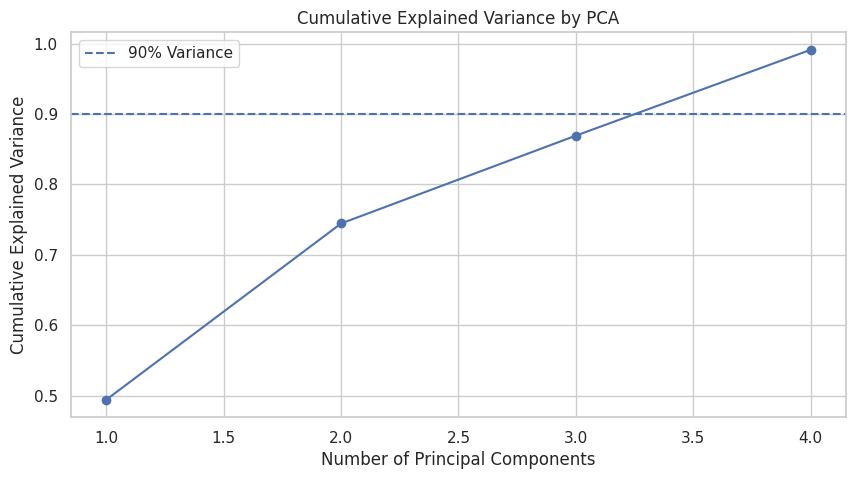

In [82]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% Variance"
)

plt.title("Cumulative Explained Variance by PCA")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.grid(True)

plt.show()

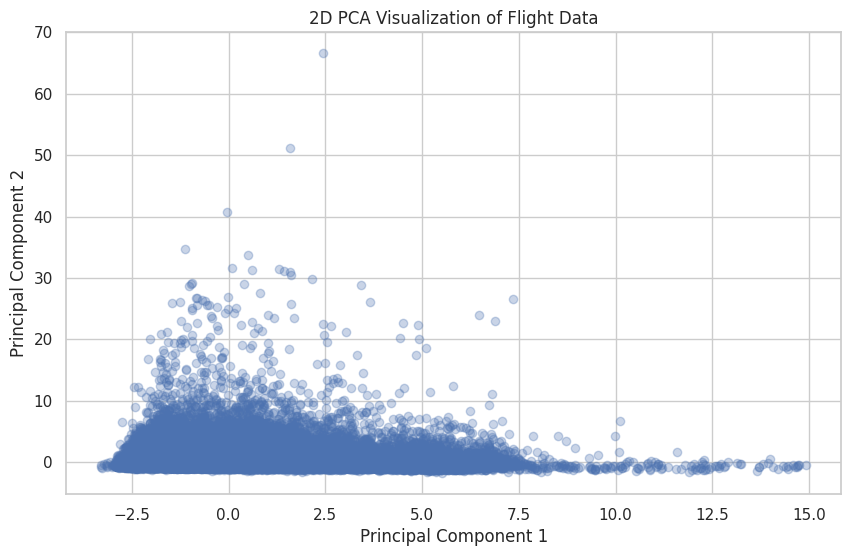

In [83]:
pca_2d = PCA(n_components=2)

pca_2d_data = pca_2d.fit_transform(scaled_data)

plt.figure(figsize=(10, 6))

plt.scatter(
    pca_2d_data[:, 0],
    pca_2d_data[:, 1],
    alpha=0.3
)

plt.title("2D PCA Visualization of Flight Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

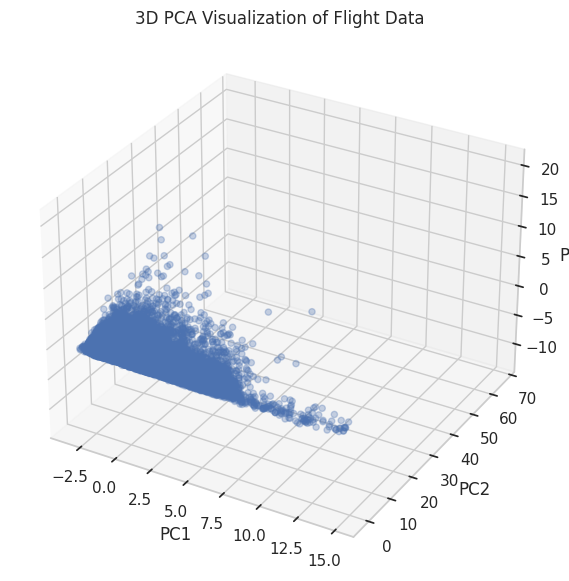

In [84]:
from mpl_toolkits.mplot3d import Axes3D

pca_3d = PCA(n_components=3)

pca_3d_data = pca_3d.fit_transform(scaled_data)

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    pca_3d_data[:, 0],
    pca_3d_data[:, 1],
    pca_3d_data[:, 2],
    alpha=0.3
)

ax.set_title("3D PCA Visualization of Flight Data")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")

plt.show()

In [85]:
pca_result_df = pd.DataFrame(
    pca_data,
    columns=[
        f"PC{i+1}" for i in range(pca_data.shape[1])
    ]
)

pca_result_df.to_csv(
    "/content/week7_pca_results.csv",
    index=False
)

explained_variance.to_csv(
    "/content/week7_explained_variance.csv",
    index=False
)

print("PCA results saved successfully!")

PCA results saved successfully!


In [86]:
print("WEEK 7 – DIMENSIONALITY REDUCTION SUMMARY")
print("----------------------------------------")

print("Original Features:", len(selected_features))
print("Features After Selection:", len(selected_feature_names))
print("Principal Components:", pca.n_components_)

print(
    "Variance Retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

print("\nWeek 7 dimensionality reduction completed successfully!")

WEEK 7 – DIMENSIONALITY REDUCTION SUMMARY
----------------------------------------
Original Features: 8
Features After Selection: 8
Principal Components: 4
Variance Retained: 99.11 %

Week 7 dimensionality reduction completed successfully!


## Conclusion

In Week 7, feature selection and dimensionality reduction were performed on the Flight Data 2024 dataset. Numerical features were selected, missing values were handled using median imputation, and the data was standardized before applying PCA.

PCA reduced the number of features while retaining at least 90% of the variance. Explained variance plots and 2D and 3D visualizations were generated to understand the principal components.

This process helped simplify the dataset while retaining important information for further analysis.


### Week 8 – Dashboard Construction

**Objective:**

To prepare summarized datasets and key performance indicators for dashboard development using Power BI. The dashboard will help visualize flight delays, monthly trends, airline performance, route analysis, and cancellation patterns. The aim is to communicate important findings through clear and meaningful visualizations.


In [3]:
import kagglehub
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download dataset
path = kagglehub.dataset_download("hrishitpatil/flight-data-2024")

# Locate CSV
csv_files = glob.glob(
    path + "/**/flight_data_2024.csv",
    recursive=True
)

file_path = csv_files[0]

# Load dataset
df = pd.read_csv(file_path, low_memory=False)

# Apply previous cleaning
df["cancellation_code"] = df["cancellation_code"].fillna("Not Cancelled")
df.loc[df["crs_elapsed_time"] < 0, "crs_elapsed_time"] = np.nan

# Recreate Week 6 features
df["route"] = df["origin"].astype("string") + "-" + df["dest"].astype("string")
df["is_weekend"] = df["day_of_week"].isin([6, 7]).astype("int8")

df["departure_delay_category"] = pd.cut(
    df["dep_delay"],
    bins=[-np.inf, 0, 15, 60, np.inf],
    labels=["On time/early", "Small delay", "Moderate delay", "High delay"]
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Using Colab cache for faster access to the 'flight-data-2024' dataset.
Dataset loaded successfully!
Shape: (7079081, 38)


In [4]:
monthly_report = df.groupby("month").agg(
    Total_Flights=("month", "count"),
    Average_Departure_Delay=("dep_delay", "mean"),
    Average_Arrival_Delay=("arr_delay", "mean")
).reset_index()

monthly_report.to_csv(
    "/content/week8_monthly_dashboard.csv",
    index=False
)

monthly_report

,month,Total_Flights,Average_Departure_Delay,Average_Arrival_Delay
0,1,547271,15.700680,10.352298
1,2,519221,7.455397,0.593455
2,3,591767,12.448736,6.504476
3,4,582205,10.810849,5.360921
4,5,609743,18.090299,14.049410
5,6,611132,16.945726,11.807215
6,7,634613,22.347979,18.092325
7,8,619025,15.310989,10.587576
8,9,582622,6.648809,0.996775
9,10,615497,5.443071,-1.282736


In [5]:
carrier_report = df.groupby("op_unique_carrier").agg(
    Total_Flights=("op_unique_carrier", "count"),
    Average_Departure_Delay=("dep_delay", "mean"),
    Average_Arrival_Delay=("arr_delay", "mean")
).reset_index()

carrier_report = carrier_report.sort_values(
    by="Average_Arrival_Delay",
    ascending=False
)

carrier_report.to_csv(
    "/content/week8_carrier_dashboard.csv",
    index=False
)

carrier_report.head(15)

,op_unique_carrier,Total_Flights,Average_Departure_Delay,Average_Arrival_Delay
1,AA,984306,20.698095,15.307916
5,F9,208624,19.002299,15.247771
3,B6,240282,17.458447,10.739642
10,OH,227971,13.936732,10.026785
6,G4,117210,14.047917,9.710381
9,NK,261103,14.957090,8.415318
11,OO,744658,11.279937,7.355390
8,MQ,279955,10.176118,6.457716
12,UA,760451,11.959024,5.742944
13,WN,1419419,11.748603,5.125102


In [6]:
route_report = df.groupby("route").agg(
    Total_Flights=("route", "count"),
    Average_Departure_Delay=("dep_delay", "mean"),
    Average_Arrival_Delay=("arr_delay", "mean")
).reset_index()

route_report = route_report.sort_values(
    by="Total_Flights",
    ascending=False
)

route_report.head(20).to_csv(
    "/content/week8_top_routes_dashboard.csv",
    index=False
)

route_report.head(20)

,route,Total_Flights,Average_Departure_Delay,Average_Arrival_Delay
4480,OGG-HNL,11642,1.721542,0.374370
2667,HNL-OGG,11634,2.269131,0.908341
3474,LAX-SFO,11526,14.511947,14.929675
6031,SFO-LAX,11499,14.755798,8.936632
3592,LGA-ORD,10971,13.192626,5.601290
4675,ORD-LGA,10969,15.596860,10.426741
3166,JFK-LAX,9915,9.103815,-2.945431
3425,LAX-JFK,9915,13.582194,3.281393
1499,DCA-BOS,9658,12.747792,5.819648
732,BOS-DCA,9657,9.498843,4.079641


In [7]:
day_report = df.groupby("day_of_week").agg(
    Total_Flights=("day_of_week", "count"),
    Average_Departure_Delay=("dep_delay", "mean"),
    Average_Arrival_Delay=("arr_delay", "mean")
).reset_index()

day_report.to_csv(
    "/content/week8_day_dashboard.csv",
    index=False
)

day_report

,day_of_week,Total_Flights,Average_Departure_Delay,Average_Arrival_Delay
0,1,1073959,12.732930,7.025018
1,2,976073,10.461914,4.393605
2,3,973179,10.415932,4.825207
3,4,1041956,13.156098,8.178983
4,5,1055419,14.662691,9.607463
5,6,911515,12.589482,6.453123
6,7,1046980,14.393926,8.774956


In [8]:
flight_status = pd.DataFrame({
    "Flight Status": [
        "Normal Flights",
        "Cancelled Flights",
        "Diverted Flights"
    ],
    "Count": [
        ((df["cancelled"] == 0) & (df["diverted"] == 0)).sum(),
        (df["cancelled"] == 1).sum(),
        (df["diverted"] == 1).sum()
    ]
})

flight_status.to_csv(
    "/content/week8_flight_status_dashboard.csv",
    index=False
)

flight_status

,Flight Status,Count
0,Normal Flights,6965267
1,Cancelled Flights,96315
2,Diverted Flights,17499


In [9]:
delay_report = df["departure_delay_category"].value_counts(
    dropna=False
).reset_index()

delay_report.columns = ["Delay Category", "Flight Count"]

delay_report.to_csv(
    "/content/week8_delay_category_dashboard.csv",
    index=False
)

delay_report

,Delay Category,Flight Count
0,On time/early,4380129
1,Small delay,1208898
2,Moderate delay,888857
3,High delay,508227
4,NaN,92970


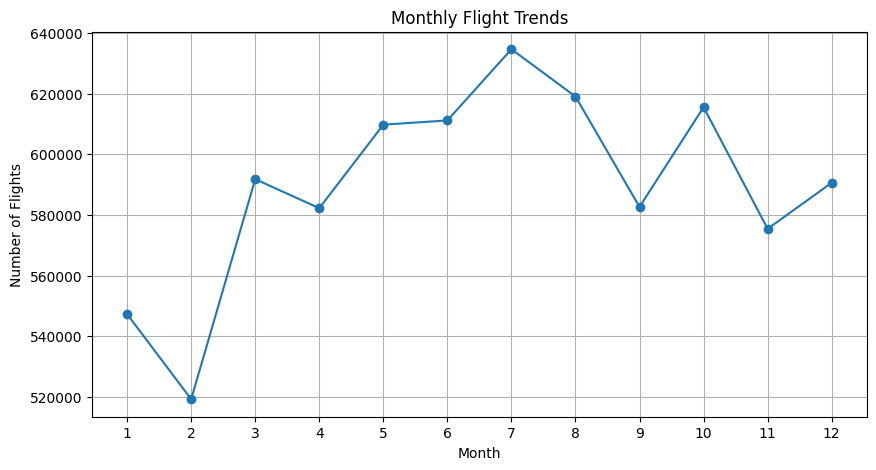

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_report["month"],
    monthly_report["Total_Flights"],
    marker="o"
)

plt.title("Monthly Flight Trends")
plt.xlabel("Month")
plt.ylabel("Number of Flights")
plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

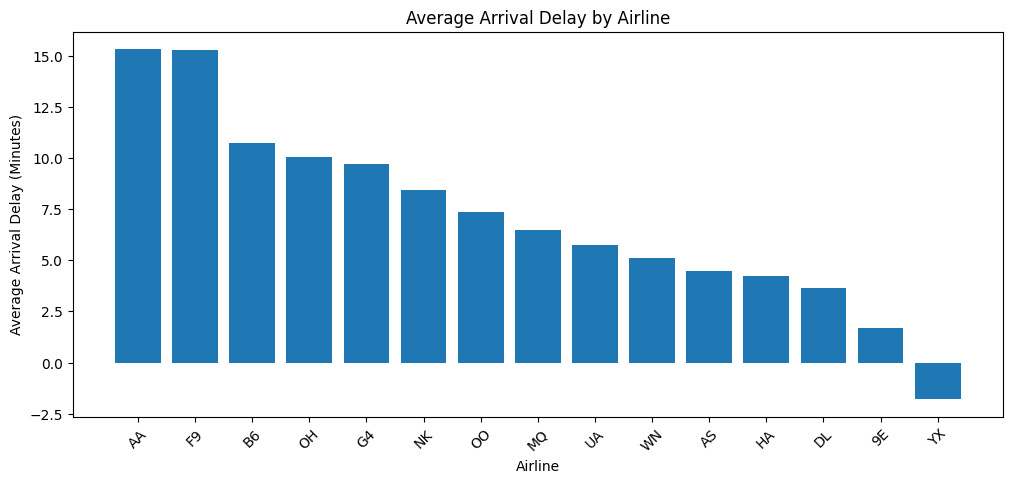

In [11]:
plt.figure(figsize=(12, 5))

plt.bar(
    carrier_report["op_unique_carrier"],
    carrier_report["Average_Arrival_Delay"]
)

plt.title("Average Arrival Delay by Airline")
plt.xlabel("Airline")
plt.ylabel("Average Arrival Delay (Minutes)")
plt.xticks(rotation=45)

plt.show()

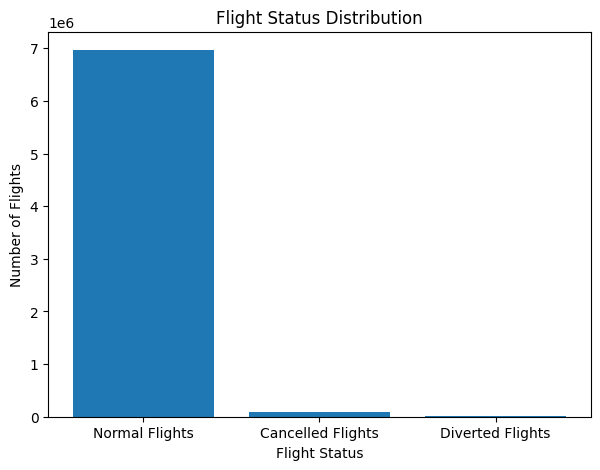

In [12]:
plt.figure(figsize=(7, 5))

plt.bar(
    flight_status["Flight Status"],
    flight_status["Count"]
)

plt.title("Flight Status Distribution")
plt.xlabel("Flight Status")
plt.ylabel("Number of Flights")

plt.show()

In [14]:
import os

print("WEEK 8 DASHBOARD FILES")

files = [
    "/content/week8_monthly_dashboard.csv",
    "/content/week8_carrier_dashboard.csv",
    "/content/week8_top_routes_dashboard.csv",
    "/content/week8_day_dashboard.csv",
    "/content/week8_flight_status_dashboard.csv",
    "/content/week8_delay_category_dashboard.csv"
]

for file in files:
    print(
        file,
        " - Created" if os.path.exists(file) else " - Not Found"
    )

WEEK 8 DASHBOARD FILES
/content/week8_monthly_dashboard.csv  - Created
/content/week8_carrier_dashboard.csv  - Created
/content/week8_top_routes_dashboard.csv  - Created
/content/week8_day_dashboard.csv  - Created
/content/week8_flight_status_dashboard.csv  - Created
/content/week8_delay_category_dashboard.csv  - Created


### Conclusion

In Week 8, we prepared summarized datasets for dashboard development using Power BI. We created reports for monthly flight trends, airline performance, popular routes, day-wise analysis, flight status, and delay categories. We also created visualizations to understand important patterns in the dataset. These outputs will support the development of an interactive dashboard and help communicate the findings clearly.
